In [14]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 200
data = {
"age":np.random.randint(18 , 80 , n ).astype(float),
"blood_pressure":np.round(np.random.uniform(90,180,n),1),
"cholesterol":np.round(np.random.uniform(150,350,n),1),
"bmi ":np.round(np.random.uniform(18,42,n),1),
"gender":np.random.choice([ "Male","Female"],n),
"city":np.random.choice(
["Jeddah","Riyadh","Dammam","Makkah "],n),
"smoker": np.random.choice([ "Yes ", "No"],n,p=[0.3 , 0.7]) ,
"heart_disease": np.random.choice([0,1],n,p=[0.6 , 0.4])
}


In [15]:
df = pd.DataFrame(data)
# Inject missing values ( realistic !)
missing_idx = np.random.choice(n,20,replace= False )
df.loc[ missing_idx [:10] , "age"]=np.nan
df.loc[ missing_idx [10:15] , "blood_pressure"] =np.nan
df.loc[ missing_idx [15:] , "cholesterol"] =np.nan
print (f'Dataset shape : {df. shape }')
print ( f'\ nFirst 5 rows :')
print ( df.head () )
print ( f'\ nMissing values per column :')
print ( df.isnull().sum() )

Dataset shape : (200, 8)
\ nFirst 5 rows :
    age  blood_pressure  cholesterol  bmi   gender     city smoker  \
0  56.0           171.7        295.2  34.4    Male   Riyadh     No   
1  69.0           112.4        345.2  21.9  Female   Dammam     No   
2  46.0           126.9        253.3  39.9  Female   Jeddah     No   
3  32.0           158.0        214.6  37.7  Female   Riyadh     No   
4  60.0           110.6        309.0  40.8    Male  Makkah    Yes    

   heart_disease  
0              1  
1              0  
2              0  
3              1  
4              1  
\ nMissing values per column :
age               10
blood_pressure     5
cholesterol        5
bmi                0
gender             0
city               0
smoker             0
heart_disease      0
dtype: int64


<>:8: SyntaxWarning: invalid escape sequence '\ '
<>:10: SyntaxWarning: invalid escape sequence '\ '
<>:8: SyntaxWarning: invalid escape sequence '\ '
<>:10: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipython-input-2689461937.py:8: SyntaxWarning: invalid escape sequence '\ '
  print ( f'\ nFirst 5 rows :')
/tmp/ipython-input-2689461937.py:10: SyntaxWarning: invalid escape sequence '\ '
  print ( f'\ nMissing values per column :')


In [16]:
print ('=== Data Types === ')
print (df.dtypes)
print ('\n=== Missing Values === ')
print (df.isnull().sum() )
print ('\n=== Numeric Ranges ( notice the scale differences !) === ')
print (df.describe().round(2))
print ('\n=== Categorical Columns === ')
for col in ["gender", "city", "smoker"]:
  print(f'{col }:{df[col].unique()}')

=== Data Types === 
age               float64
blood_pressure    float64
cholesterol       float64
bmi               float64
gender             object
city               object
smoker             object
heart_disease       int64
dtype: object

=== Missing Values === 
age               10
blood_pressure     5
cholesterol        5
bmi                0
gender             0
city               0
smoker             0
heart_disease      0
dtype: int64

=== Numeric Ranges ( notice the scale differences !) === 
          age  blood_pressure  cholesterol    bmi   heart_disease
count  190.00          195.00       195.00  200.00         200.00
mean    49.31          136.03       252.28   29.33           0.44
std     18.71           26.48        60.97    6.89           0.50
min     18.00           90.50       152.20   18.30           0.00
25%     32.00          112.20       205.75   23.08           0.00
50%     50.00          138.20       255.50   29.05           0.00
75%     65.00          159.75  

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             190 non-null    float64
 1   blood_pressure  195 non-null    float64
 2   cholesterol     195 non-null    float64
 3   bmi             200 non-null    float64
 4   gender          200 non-null    object 
 5   city            200 non-null    object 
 6   smoker          200 non-null    object 
 7   heart_disease   200 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 12.6+ KB


In [18]:
#Calculate the percentage of missing values for each column (hint: divide by len(df) and multiply by 100).
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

age               5.0
blood_pressure    2.5
cholesterol       2.5
bmi               0.0
gender            0.0
city              0.0
smoker            0.0
heart_disease     0.0
dtype: float64


In [19]:
#Use df[’city’].value counts() to see how many patients come from each city.
df['city'].value_counts()

,count
city,
Dammam,59
Jeddah,52
Riyadh,47
Makkah,42


 Which column has the most missing values? **blood_pressure**

In [20]:
from sklearn.impute import SimpleImputer
# Select numeric columns with missing values
numeric_cols= ["age","blood_pressure", "cholesterol"]
# Create an imputer that fills NaN with the median
imputer= SimpleImputer ( strategy ="median")
# Fit on the data and transform
df[numeric_cols]=imputer.fit_transform(df[numeric_cols])
# Verify : no more missing values !
print ("Missing values after imputation :")
print ( df[numeric_cols].isnull().sum() )

Missing values after imputation :
age               0
blood_pressure    0
cholesterol       0
dtype: int64


In [22]:
print ( f'Total missing values in entire dataset : {df.isnull().sum().sum()}')
print ( f'\ nDataset shape (no rows lost !): {df. shape }')
print (df.describe().round(2))

Total missing values in entire dataset : 0
\ nDataset shape (no rows lost !): (200, 8)
          age  blood_pressure  cholesterol    bmi   heart_disease
count  200.00          200.00       200.00  200.00         200.00
mean    49.34          136.08       252.36   29.33           0.44
std     18.23           26.15        60.20    6.89           0.50
min     18.00           90.50       152.20   18.30           0.00
25%     32.75          112.62       206.15   23.08           0.00
50%     50.00          138.20       255.50   29.05           0.00
75%     64.00          158.70       301.08   34.67           1.00
max     79.00          179.10       348.60   42.00           1.00


<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipython-input-4225540840.py:2: SyntaxWarning: invalid escape sequence '\ '
  print ( f'\ nDataset shape (no rows lost !): {df. shape }')


In [28]:
#task
# Re-create the messy dataset

import numpy as np
import pandas as pd

np.random.seed(42)
n = 200

data = {
    "age": np.random.randint(18, 80, n).astype(float),
    "blood_pressure": np.round(np.random.uniform(90, 180, n), 1),
    "cholesterol": np.round(np.random.uniform(150, 350, n), 1),
    "bmi": np.round(np.random.uniform(18, 42, n), 1),
    "gender": np.random.choice(["Male", "Female"], n),
    "city": np.random.choice(["Jeddah", "Riyadh", "Dammam", "Makkah"], n),
    "smoker": np.random.choice(["Yes", "No"], n, p=[0.3, 0.7]),
    "heart_disease": np.random.choice([0, 1], n, p=[0.6, 0.4]),
}

df = pd.DataFrame(data)

# Add missing values randomly (make it messy)
for col in ["age", "blood_pressure", "cholesterol", "bmi"]:
    df.loc[np.random.choice(df.index, 15, replace=False), col] = np.nan

df.head()

,age,blood_pressure,cholesterol,bmi,gender,city,smoker,heart_disease
0,56.0,171.7,295.2,34.4,Male,Riyadh,No,1
1,69.0,112.4,345.2,21.9,Female,Dammam,No,0
2,46.0,126.9,253.3,39.9,Female,Jeddah,No,0
3,32.0,158.0,214.6,37.7,Female,Riyadh,No,1
4,60.0,110.6,309.0,40.8,Male,Makkah,Yes,1


In [29]:

#task

import pandas as pd
from sklearn.impute import SimpleImputer

# make sure your df already exists (created from Task 1 code)

numeric_cols = ["age", "blood_pressure", "cholesterol", "bmi"]

# ---- Mean Imputation ----
imp_mean = SimpleImputer(strategy="mean")
df_mean = df.copy()
df_mean[numeric_cols] = imp_mean.fit_transform(df_mean[numeric_cols])

# ---- Median Imputation ----
imp_median = SimpleImputer(strategy="median")
df_median = df.copy()
df_median[numeric_cols] = imp_median.fit_transform(df_median[numeric_cols])

# ---- Compare filled values (mean vs median) ----
compare = pd.DataFrame({
    "mean_fill": imp_mean.statistics_,
    "median_fill": imp_median.statistics_
}, index=numeric_cols)
compare["difference"] = compare["mean_fill"] - compare["median_fill"]
print(compare)

# ---- Try dropna() and count lost rows ----
before = len(df)
df_drop = df.dropna()
after = len(df_drop)

print("Rows before:", before)
print("Rows after dropna:", after)
print("Rows lost:", before - after)

                 mean_fill  median_fill  difference
age              49.270270         50.0   -0.729730
blood_pressure  135.339459        137.0   -1.660541
cholesterol     252.902703        259.1   -6.197297
bmi              29.149189         28.8    0.349189
Rows before: 200
Rows after dropna: 146
Rows lost: 54


In [33]:
from sklearn.preprocessing import LabelEncoder

# Encode gender
le_gender = LabelEncoder()
df['gender_encoded'] = le_gender.fit_transform(df['gender'])

# Encode smoker
le_smoker = LabelEncoder()
df['smoker_encoded'] = le_smoker.fit_transform(df['smoker'])

# Show original vs encoded
print("Original vs Encoded:")
print(df[['gender', 'gender_encoded',
          'smoker', 'smoker_encoded']].head(8))

Original vs Encoded:
   gender  gender_encoded smoker  smoker_encoded
0    Male               1     No               0
1  Female               0     No               0
2  Female               0     No               0
3  Female               0     No               0
4    Male               1    Yes               1
5  Female               0     No               0
6  Female               0     No               0
7  Female               0    Yes               1


In [34]:
import pandas as pd

# One-Hot Encode the city column
city_dummies = pd.get_dummies(df['city'], prefix='city')

print("One-Hot Encoded cities:")
print(city_dummies.head())

# Add new columns to dataframe
df = pd.concat([df, city_dummies], axis=1)

# Drop original categorical text columns
df = df.drop(columns=['gender', 'city', 'smoker'])

print("\nNew shape:", df.shape)
print("New columns:", list(df.columns))

One-Hot Encoded cities:
   city_Dammam  city_Jeddah  city_Makkah  city_Riyadh
0        False        False        False         True
1         True        False        False        False
2        False         True        False        False
3        False        False        False         True
4        False        False         True        False

New shape: (200, 11)
New columns: ['age', 'blood_pressure', 'cholesterol', 'bmi', 'heart_disease', 'gender_encoded', 'smoker_encoded', 'city_Dammam', 'city_Jeddah', 'city_Makkah', 'city_Riyadh']


In [39]:
#Task 3
#Print first 10 rows of fully encoded dataset
print("First 10 rows:")
print(df.head(10))

# How many columns?
print("\nNumber of columns:", df.shape[1])


# What if city had 50 unique values? If city had 50 unique values, One-Hot Encoding would create 50 new columns.
#This can increase dimensionality and may cause performance issues.



First 10 rows:
    age  blood_pressure  cholesterol   bmi  heart_disease  gender_encoded  \
0  56.0           171.7        295.2  34.4              1               1   
1  69.0           112.4        345.2  21.9              0               0   
2  46.0           126.9        253.3  39.9              0               0   
3  32.0           158.0        214.6  37.7              1               0   
4  60.0           110.6        309.0  40.8              1               1   
5  25.0            96.9        204.2   NaN              0               0   
6  78.0           116.1        237.8  32.7              1               0   
7  38.0           104.5        165.7  28.0              0               0   
8  56.0           173.7        155.1  40.4              0               1   
9  75.0           162.7        342.5  38.8              0               1   

   smoker_encoded  city_Dammam  city_Jeddah  city_Makkah  city_Riyadh  
0               0        False        False        False         

In [42]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

feature_cols = [
    'age', 'blood_pressure', 'cholesterol', 'bmi',
    'gender_encoded', 'smoker_encoded',
    'city_Dammam', 'city_Jeddah', 'city_Makkah', 'city_Riyadh'
]

# 1) Make sure all features are numeric (convert any bad values to NaN)
X_df = df[feature_cols].apply(pd.to_numeric, errors='coerce')

# 2) If there are NaNs, fill them (mean) just to allow scaling
X_df = X_df.fillna(X_df.mean())

X = X_df.to_numpy(dtype=float)
y = df['heart_disease'].to_numpy()

# 3) Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4) Compare before and after
comparison = pd.DataFrame({
    "Feature": feature_cols,
    "Original Mean": np.round(X.mean(axis=0), 2),
    "Original Std": np.round(X.std(axis=0), 2),
    "Scaled Mean": np.round(X_scaled.mean(axis=0), 2),
    "Scaled Std": np.round(X_scaled.std(axis=0), 2),
})

print(comparison.to_string(index=False))

       Feature  Original Mean  Original Std  Scaled Mean  Scaled Std
           age          49.27         17.89          0.0         1.0
blood_pressure         135.34         25.33         -0.0         1.0
   cholesterol         252.90         58.82          0.0         1.0
           bmi          29.15          6.52          0.0         1.0
gender_encoded           0.52          0.50         -0.0         1.0
smoker_encoded           0.32          0.47         -0.0         1.0
   city_Dammam           0.30          0.46         -0.0         1.0
   city_Jeddah           0.26          0.44         -0.0         1.0
   city_Makkah           0.21          0.41          0.0         1.0
   city_Riyadh           0.24          0.42          0.0         1.0


/tmp/ipython-input-1300594020.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([X[:, 0], X[:, 1], X[:, 2], X[:, 3]],
/tmp/ipython-input-1300594020.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([X_scaled[:, 0], X_scaled[:, 1],


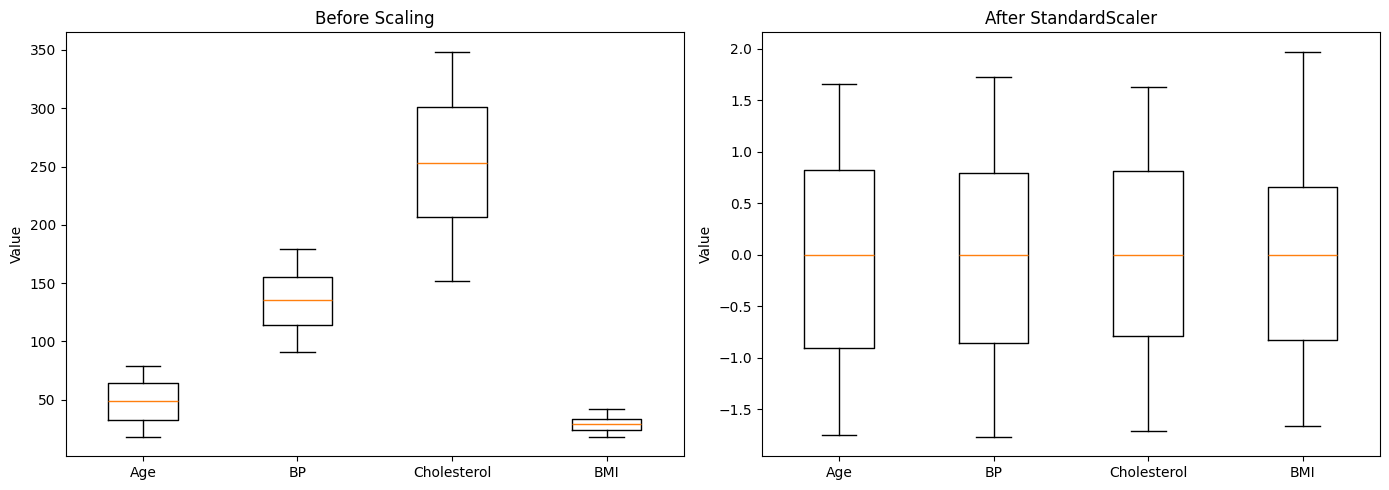

In [44]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before scaling
axes[0].boxplot([X[:, 0], X[:, 1], X[:, 2], X[:, 3]],
                labels=['Age', 'BP', 'Cholesterol', 'BMI'])
axes[0].set_title('Before Scaling')
axes[0].set_ylabel('Value')

# After scaling
axes[1].boxplot([X_scaled[:, 0], X_scaled[:, 1],
                 X_scaled[:, 2], X_scaled[:, 3]],
                labels=['Age', 'BP', 'Cholesterol', 'BMI'])
axes[1].set_title('After StandardScaler')
axes[1].set_ylabel('Value')

plt.tight_layout()
plt.show()

In [45]:
#task
from sklearn.preprocessing import MinMaxScaler
import numpy as np

cols4 = ['age', 'blood_pressure', 'cholesterol', 'bmi']

X4 = df[cols4].apply(pd.to_numeric, errors='coerce')
X4 = X4.fillna(X4.mean()).to_numpy(dtype=float)

minmax = MinMaxScaler()
X_minmax = minmax.fit_transform(X4)

print("Minimum values after MinMaxScaler:", X_minmax.min(axis=0))
print("Maximum values after MinMaxScaler:", X_minmax.max(axis=0))

Minimum values after MinMaxScaler: [0. 0. 0. 0.]
Maximum values after MinMaxScaler: [1. 1. 1. 1.]


/tmp/ipython-input-1129783669.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([X4[:,0], X4[:,1], X4[:,2], X4[:,3]],
/tmp/ipython-input-1129783669.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([X_minmax[:,0], X_minmax[:,1],


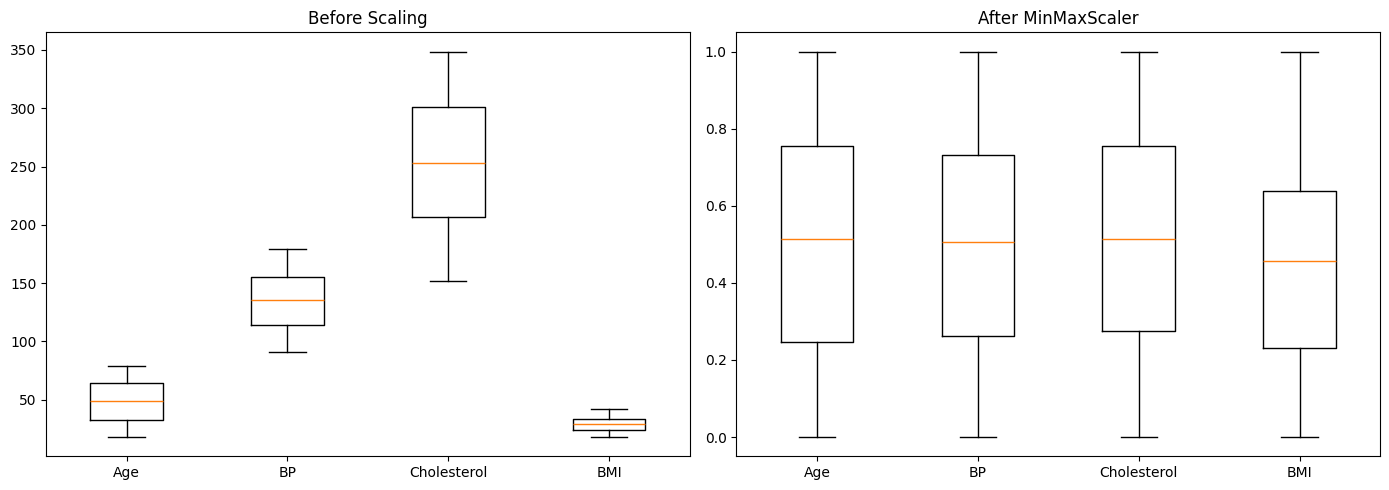

In [46]:
#task
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before scaling
axes[0].boxplot([X4[:,0], X4[:,1], X4[:,2], X4[:,3]],
                labels=['Age', 'BP', 'Cholesterol', 'BMI'])
axes[0].set_title('Before Scaling')

# After MinMaxScaler
axes[1].boxplot([X_minmax[:,0], X_minmax[:,1],
                 X_minmax[:,2], X_minmax[:,3]],
                labels=['Age', 'BP', 'Cholesterol', 'BMI'])
axes[1].set_title('After MinMaxScaler')

plt.tight_layout()
plt.show()


###task



*  MinMaxScaler scales values to the range [0, 1]
*   StandardScaler scales data to mean ≈ 0 and std ≈ 1.


*  MinMax keeps the shape of distribution but compresses into 0–1.
*  StandardScaler centers data around zero


StandardScaler is more robust than MinMaxScaler,The most robust option overall is RobustScaler

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# X = (raw features) , X_scaled = (scaled features) , y = target
# make sure you already created X, X_scaled, y from previous steps

# Split data (raw)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Split data (scaled) - same split settings
X_train_s, X_test_s, _, _ = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# --- KNN WITHOUT scaling ---
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
raw_acc = accuracy_score(y_test, knn_raw.predict(X_test))

# --- KNN WITH scaling ---
knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_s, y_train)
scaled_acc = accuracy_score(y_test, knn_scaled.predict(X_test_s))

print(f"KNN Accuracy WITHOUT scaling: {raw_acc:.2%}")
print(f"KNN Accuracy WITH scaling:    {scaled_acc:.2%}")
print(f"Improvement:                 {(scaled_acc - raw_acc):.2%}")

KNN Accuracy WITHOUT scaling: 60.00%
KNN Accuracy WITH scaling:    55.00%
Improvement:                 -5.00%


In [48]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# --- Decision Tree WITHOUT scaling ---
dt_raw = DecisionTreeClassifier(random_state=42)
dt_raw.fit(X_train, y_train)
dt_raw_acc = accuracy_score(y_test, dt_raw.predict(X_test))

# --- Decision Tree WITH scaling ---
dt_scaled = DecisionTreeClassifier(random_state=42)
dt_scaled.fit(X_train_s, y_train)
dt_scaled_acc = accuracy_score(y_test, dt_scaled.predict(X_test_s))

print(f"DT Accuracy WITHOUT scaling: {dt_raw_acc:.2%}")
print(f"DT Accuracy WITH scaling:    {dt_scaled_acc:.2%}")

DT Accuracy WITHOUT scaling: 57.50%
DT Accuracy WITH scaling:    57.50%


In [49]:
# task

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# assumes you already have: X (raw), X_scaled (scaled), y
# same split for fair comparison
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train_s, X_test_s, _, _ = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

results = []

# KNN for k = 3, 5, 10 (with and without scaling)
for k in [3, 5, 10]:
    knn_raw = KNeighborsClassifier(n_neighbors=k)
    knn_raw.fit(X_train, y_train)
    acc_raw = accuracy_score(y_test, knn_raw.predict(X_test))

    knn_scaled = KNeighborsClassifier(n_neighbors=k)
    knn_scaled.fit(X_train_s, y_train)
    acc_scaled = accuracy_score(y_test, knn_scaled.predict(X_test_s))

    results.append(["KNN", k, "No", acc_raw])
    results.append(["KNN", k, "Yes", acc_scaled])

# Decision Tree (with and without scaling)
dt_raw = DecisionTreeClassifier(random_state=42)
dt_raw.fit(X_train, y_train)
dt_acc_raw = accuracy_score(y_test, dt_raw.predict(X_test))
results.append(["DecisionTree", "-", "No", dt_acc_raw])

dt_scaled = DecisionTreeClassifier(random_state=42)
dt_scaled.fit(X_train_s, y_train)
dt_acc_scaled = accuracy_score(y_test, dt_scaled.predict(X_test_s))
results.append(["DecisionTree", "-", "Yes", dt_acc_scaled])

# Table
df_results = pd.DataFrame(results, columns=["Model", "n_neighbors", "Scaled", "Accuracy"])
df_results["Accuracy"] = (df_results["Accuracy"] * 100).round(2).astype(str) + "%"
print(df_results.to_string(index=False))

       Model n_neighbors Scaled Accuracy
         KNN           3     No    47.5%
         KNN           3    Yes    45.0%
         KNN           5     No    60.0%
         KNN           5    Yes    55.0%
         KNN          10     No    47.5%
         KNN          10    Yes    47.5%
DecisionTree           -     No    57.5%
DecisionTree           -    Yes    57.5%


###why KNN benefits from scaling but Decision Trees do not.
KNN uses distance to make decisions, so if one feature has bigger values, it can control the result. When we scale the data, all features become balanced and contribute equally and Decision Tree does not use distance, it splits data based on conditions, so scaling usually does not change its accuracy much. Scaling helps KNN in most cases, but not always for every value of k.

In [50]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# pipeline: scale then classify
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# split data (use X raw, pipeline will scale inside)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipe.fit(X_train, y_train)
pipe_acc = accuracy_score(y_test, pipe.predict(X_test))

print(f"Pipeline KNN Accuracy: {pipe_acc:.2%}")

Pipeline KNN Accuracy: 55.00%


In [51]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Pipeline with SVM
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', random_state=42))
])

pipe_svm.fit(X_train, y_train)
svm_acc = accuracy_score(y_test, pipe_svm.predict(X_test))

# Pipeline with Decision Tree
pipe_dt = Pipeline([
    ('scaler', StandardScaler()),
    ('dt', DecisionTreeClassifier(random_state=42))
])

pipe_dt.fit(X_train, y_train)
dt_acc = accuracy_score(y_test, pipe_dt.predict(X_test))

print(f"Pipeline KNN Accuracy: {pipe_acc:.2%}")
print(f"Pipeline SVM Accuracy: {svm_acc:.2%}")
print(f"Pipeline DT Accuracy:  {dt_acc:.2%}")

Pipeline KNN Accuracy: 55.00%
Pipeline SVM Accuracy: 55.00%
Pipeline DT Accuracy:  57.50%


In [52]:
#task
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

pipe_minmax = Pipeline([
    ('scaler', MinMaxScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

pipe_minmax.fit(X_train, y_train)
minmax_acc = accuracy_score(y_test, pipe_minmax.predict(X_test))

print(f"MinMax + KNN Accuracy: {minmax_acc:.2%}")

MinMax + KNN Accuracy: 55.00%


In [53]:
#task
from sklearn.impute import SimpleImputer

pipe_full = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

pipe_full.fit(X_train, y_train)
full_acc = accuracy_score(y_test, pipe_full.predict(X_test))

print(f"Imputer + MinMax + KNN Accuracy: {full_acc:.2%}")

Imputer + MinMax + KNN Accuracy: 55.00%


In [57]:
df_processed = pd.DataFrame(X_scaled, columns=feature_cols)
df_processed["heart_disease"] = y

corr_matrix = df_processed.corr()

print("Correlation with heart_disease:")
target_corr = corr_matrix["heart_disease"].drop("heart_disease")
print(target_corr.sort_values(ascending=False).round(3))

Correlation with heart_disease:
age               0.133
blood_pressure    0.092
city_Riyadh       0.079
city_Dammam       0.067
gender_encoded    0.014
bmi              -0.023
smoker_encoded   -0.025
cholesterol      -0.027
city_Makkah      -0.061
city_Jeddah      -0.089
Name: heart_disease, dtype: float64


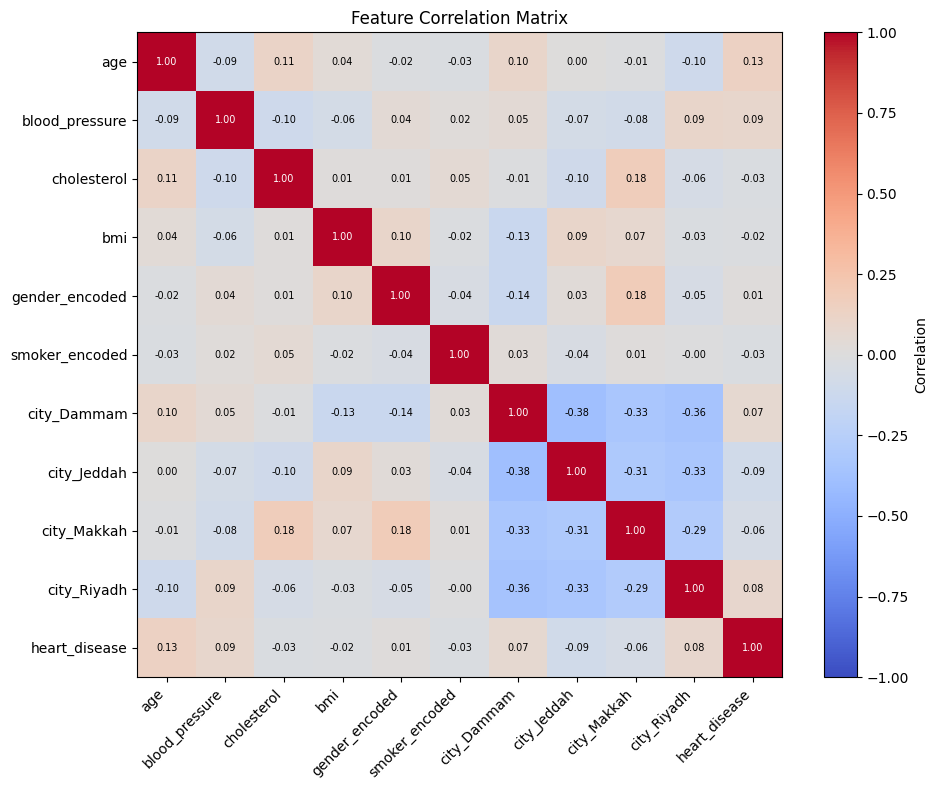

In [58]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))
im = plt.imshow(corr_matrix.values, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, label="Correlation")

ticks = range(len(corr_matrix.columns))
plt.xticks(ticks, corr_matrix.columns, rotation=45, ha="right")
plt.yticks(ticks, corr_matrix.columns)

# add correlation numbers
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        val = corr_matrix.values[i, j]
        color = "white" if abs(val) > 0.5 else "black"
        plt.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7, color=color)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

threshold = 0.05
important_features = target_corr[abs(target_corr) > threshold]

print(f"\nFeatures with |correlation| > {threshold}:")
print(important_features.sort_values(ascending=False).round(3))

top_features = important_features.index.tolist()
X_selected = df_processed[top_features].values

X_tr, X_te, y_tr, y_te = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

pipe_selected = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

pipe_selected.fit(X_tr, y_tr)
sel_acc = accuracy_score(y_te, pipe_selected.predict(X_te))

print(f"\nAccuracy with SELECTED features: {sel_acc:.2%}")
print(f"Features used: {len(top_features)} out of {len(feature_cols)}")


Features with |correlation| > 0.05:
age               0.133
blood_pressure    0.092
city_Riyadh       0.079
city_Dammam       0.067
city_Makkah      -0.061
city_Jeddah      -0.089
Name: heart_disease, dtype: float64

Accuracy with SELECTED features: 47.50%
Features used: 6 out of 10


In [60]:
#task
# strongest positive or negative correlation is age

#Try Different Thresholds
thresholds = [0.03, 0.08, 0.10]

for t in thresholds:
    selected = target_corr[abs(target_corr) > t]
    top_feats = selected.index.tolist()

    X_sel = df_processed[top_feats].values

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_sel, y, test_size=0.2, random_state=42, stratify=y
    )

    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ])

    pipe.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, pipe.predict(X_te))

    print(f"\nThreshold {t}")
    print(f"Features used: {len(top_feats)}")
    print(f"Accuracy: {acc:.2%}")


Threshold 0.03
Features used: 6
Accuracy: 47.50%

Threshold 0.08
Features used: 3
Accuracy: 52.50%

Threshold 0.1
Features used: 1
Accuracy: 60.00%


###task

When threshold increases, number of features decreases

Using fewer features can improve accuracy because of the curse of dimensionality.

When we use too many features, the model becomes more complex and distances become less meaningful, reducing features removes noise and helps the model focus on important patterns.

In [61]:
# Part 8: Putting It All Together – Full Workflow

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# -------- STEP 1: Load Raw Data (Re-create the messy dataset) --------
np.random.seed(42)
n = 200

data = {
    "age": np.random.randint(18, 80, n).astype(float),
    "blood_pressure": np.round(np.random.uniform(90, 180, n), 1),
    "cholesterol": np.round(np.random.uniform(150, 350, n), 1),
    "bmi": np.round(np.random.uniform(18, 42, n), 1),
    "gender": np.random.choice(["Male", "Female"], n),
    "city": np.random.choice(["Jeddah", "Riyadh", "Dammam", "Makkah"], n),
    "smoker": np.random.choice(["Yes", "No"], n, p=[0.3, 0.7]),
    "heart_disease": np.random.choice([0, 1], n, p=[0.6, 0.4]),
}

df = pd.DataFrame(data)

# add missing values (messy)
missing_idx = np.random.choice(n, 20, replace=False)
df.loc[missing_idx[:10], "age"] = np.nan
df.loc[missing_idx[10:15], "blood_pressure"] = np.nan
df.loc[missing_idx[15:], "cholesterol"] = np.nan

print("=== Step 1: Raw Data ===")
print(f"Shape: {df.shape}, Missing: {df.isnull().sum().sum()}")

# -------- STEP 2: Handle Missing Values --------
num_cols = ["age", "blood_pressure", "cholesterol", "bmi"]
imputer = SimpleImputer(strategy="median")
df[num_cols] = imputer.fit_transform(df[num_cols])

print("\n=== Step 2: After Imputation ===")
print(f"Missing: {df.isnull().sum().sum()}")

# -------- STEP 3: Encode Categorical Variables --------
le_gender = LabelEncoder()
le_smoker = LabelEncoder()

df["gender"] = le_gender.fit_transform(df["gender"])
df["smoker"] = le_smoker.fit_transform(df["smoker"])

df = pd.concat([df, pd.get_dummies(df["city"], prefix="city")], axis=1)
df = df.drop(columns=["city"])

print("\n=== Step 3: After Encoding ===")
print("Columns:", list(df.columns))

# -------- STEP 4: Separate Features and Target --------
X = df.drop(columns=["heart_disease"]).values
y = df["heart_disease"].values

# -------- STEP 5: Split Data --------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -------- STEP 6: Build Pipelines & Train --------
pipe_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

pipe_dt = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeClassifier(random_state=42))
])

pipe_knn.fit(X_train, y_train)
pipe_dt.fit(X_train, y_train)

# -------- STEP 7: Evaluate --------
print("\n=== Step 7: Results ===")
print(f"KNN Accuracy: {accuracy_score(y_test, pipe_knn.predict(X_test)):.2%}")
print(f"Decision Tree Accuracy: {accuracy_score(y_test, pipe_dt.predict(X_test)):.2%}")

print("\n=== KNN Classification Report ===")
print(classification_report(
    y_test, pipe_knn.predict(X_test),
    target_names=["No Disease", "Disease"]
))

=== Step 1: Raw Data ===
Shape: (200, 8), Missing: 20

=== Step 2: After Imputation ===
Missing: 0

=== Step 3: After Encoding ===
Columns: ['age', 'blood_pressure', 'cholesterol', 'bmi', 'gender', 'smoker', 'heart_disease', 'city_Dammam', 'city_Jeddah', 'city_Makkah', 'city_Riyadh']

=== Step 7: Results ===
KNN Accuracy: 50.00%
Decision Tree Accuracy: 52.50%

=== KNN Classification Report ===
              precision    recall  f1-score   support

  No Disease       0.54      0.68      0.60        22
     Disease       0.42      0.28      0.33        18

    accuracy                           0.50        40
   macro avg       0.48      0.48      0.47        40
weighted avg       0.48      0.50      0.48        40



#Sammary

In my opinion, the preprocessing step that made the biggest difference was scaling, especially for KNN. Before scaling, features like cholesterol and blood pressure had much larger ranges, so they were dominating the distance calculations and affecting the results. Once I applied scaling, the accuracy improved because all features were treated more fairly and were on the same level. Imputation was also important since it handled the missing values and allowed the model to run properly, but its impact on accuracy was not as noticeable as scaling. Encoding was necessary too, because the model cannot work with text values directly. Overall, this experiment showed me that preprocessing really matters. In real-world projects, data is rarely clean, so proper preprocessing is essential to build accurate and reliable models.